# 03 · Resolution speed: do limited-English tracts wait longer?

**Question:** for the *same type of request*, do tracts with more limited-English households wait longer for the city to close it, after accounting for income and renter share?

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from lifelines import KaplanMeierFitter, CoxPHFitter
pd.set_option("display.max_columns", 50, "display.width", 150)
PROC = "../data/processed"
con = duckdb.connect()

## 1. Build the analysis dataset
Each row is one request. We keep requests that:
- fall in a City-of-LA tract with at least 100 households and a known median income (from notebook 2),
- have valid dates (`NOT bad_dates`) and were not cancelled.

**Censoring means:** we only partly observe an outcome. For a request that is still open, we know it has waited at least X days but not how long it will take in total. Dropping such requests would delete the slowest cases and make the city look faster, so survival analysis keeps them, recording how long each was watched and whether it closed during that time.

**Censoring clock:** requests have different amounts of follow-up time. We stop the clock at the latest close date in the data (`OBS_END`). A request with no close date has waited *at least* until then.

In [2]:
con.execute(f"""
CREATE OR REPLACE TABLE speed AS
SELECT r.sr_number, r.request_type, r.created_at, r.closed_at, r.days_to_close,
       r.is_driver_report, c.geoid, c.lep_share, c.median_income, c.renter_share, c.frac_in_city
FROM '{PROC}/requests_clean.parquet' r
JOIN '{PROC}/request_tract.parquet' t USING (sr_number)
JOIN '{PROC}/tracts_city.parquet' c ON c.geoid = t.geoid
WHERE t.in_city_tract AND NOT r.bad_dates AND NOT r.is_cancelled
  AND c.households >= 100 AND c.median_income IS NOT NULL AND c.lep_share IS NOT NULL
""")
OBS_END = con.sql("SELECT max(closed_at) FROM speed").fetchone()[0]
print("observation ends:", OBS_END)
df = con.sql(f"""
SELECT *, year(created_at) AS year,
       coalesce(days_to_close, date_diff('second', created_at, TIMESTAMP '{OBS_END}') / 86400.0) AS duration,
       (closed_at IS NOT NULL) AS closed
FROM speed
""").df()
print(f"{len(df):,} requests in {df.geoid.nunique():,} tracts | still open at end: {(~df.closed).sum():,}")
df.groupby("request_type").agg(n=("closed","size"), open_share=("closed", lambda s: round(1-s.mean(),4)),
                               driver_share=("is_driver_report","mean")).sort_values("n", ascending=False).round(3)

observation ends: 2025-10-16 00:02:44
3,924,812 requests in 1,091 tracts | still open at end: 110,111


,n,open_share,driver_share
request_type,,,
Bulky Items,1880089,0.009,0.002
Graffiti Removal,859041,0.005,0.557
Metal/Household Appliances,324229,0.003,0.000
Illegal Dumping Pickup,305262,0.029,0.027
Homeless Encampment,215720,0.201,0.002
Electronic Waste,113358,0.005,0.001
Dead Animal Removal,87410,0.001,0.001
Multiple Streetlight Issue,60296,0.335,0.000
Single Streetlight Issue,52176,0.274,0.000




## 2. Excluding driver self-reports from the speed comparison

In [3]:
g = df[df.request_type == "Graffiti Removal"]
print(g.groupby("is_driver_report").duration.describe(percentiles=[.5,.9]).round(2))

                     count   mean    std  min   50%   90%      max
is_driver_report                                                  
False             380443.0  12.09  79.28  0.0  1.57  7.94  1383.14
True              478598.0   0.95  11.52  0.0  0.00  0.01   715.13


City drivers log a problem they have *already fixed*, so those tickets open and close within minutes (median ≈ 0 days). They are 56% of graffiti requests and their share varies by neighborhood. Mixing them in would measure how often drivers file reports, not how fast residents are served.

**Decision:** the main analysis uses **resident-reported requests only** (`NOT is_driver_report`). Driver reports come back in a sensitivity check.


In [4]:
res = df[~df.is_driver_report].copy()
MAIN = ["Bulky Items", "Illegal Dumping Pickup", "Metal/Household Appliances", "Electronic Waste", "Graffiti Removal"]
SLOW = ["Homeless Encampment", "Multiple Streetlight Issue", "Single Streetlight Issue"]
res = res[res.request_type.isin(MAIN + SLOW)].copy()
res["group"] = np.where(res.request_type.isin(MAIN), "main", "slow")
# limited-English quintiles are defined across TRACTS (each quintile has about the same number of tracts)
tr = res[["geoid","lep_share"]].drop_duplicates()
tr["quintile"] = pd.qcut(tr.lep_share, 5, labels=[1,2,3,4,5]).astype(int)
res = res.merge(tr[["geoid","quintile"]], on="geoid")
print(tr.groupby("quintile").lep_share.agg(["min","max","count"]).round(3))
print(f"\n{len(res):,} resident-reported requests in the analysis")

            min    max  count
quintile                     
1         0.000  0.043    219
2         0.044  0.093    218
3         0.093  0.154    218
4         0.154  0.241    218
5         0.241  0.674    218

3,318,709 resident-reported requests in the analysis



## 3. Descriptive results: Kaplan–Meier medians and closure rates
For each request type and quintile: the median time-to-close from a Kaplan–Meier fit (which counts open requests as "still waiting"), and the share closed within 7, 30 and 90 days.

In [5]:
rows = []
for (rt, q), d in res.groupby(["request_type", "quintile"]):
    km = KaplanMeierFitter().fit(d.duration, d.closed)
    rows.append(dict(request_type=rt, quintile=q, n=len(d), median_days=km.median_survival_time_,
                     closed_7d=(d.closed & (d.duration <= 7)).mean(),
                     closed_30d=(d.closed & (d.duration <= 30)).mean(),
                     closed_90d=(d.closed & (d.duration <= 90)).mean(),
                     still_open=(~d.closed).mean()))
km_tbl = pd.DataFrame(rows)
km_tbl.round(3)

,request_type,quintile,n,median_days,closed_7d,closed_30d,closed_90d,still_open
0,Bulky Items,1,379834,2.237,0.927,0.989,0.991,0.007
1,Bulky Items,2,428213,2.236,0.922,0.987,0.990,0.008
2,Bulky Items,3,387893,2.282,0.920,0.986,0.989,0.008
3,Bulky Items,4,364917,2.149,0.917,0.983,0.987,0.010
4,Bulky Items,5,315263,2.112,0.912,0.979,0.983,0.011
5,Electronic Waste,1,24398,2.242,0.928,0.994,0.994,0.006
6,Electronic Waste,2,27537,2.172,0.934,0.995,0.995,0.005
7,Electronic Waste,3,23409,2.144,0.935,0.994,0.995,0.005
8,Electronic Waste,4,21218,2.003,0.942,0.993,0.994,0.006
9,Electronic Waste,5,16735,1.962,0.942,0.993,0.994,0.006


In [6]:
piv = km_tbl.pivot(index="request_type", columns="quintile", values="median_days").round(2)
piv["Q5 minus Q1 (days)"] = (piv[5] - piv[1]).round(2)
piv.loc[MAIN + SLOW]

quintile,1,2,3,4,5,Q5 minus Q1 (days)
request_type,,,,,,
Bulky Items,2.24,2.24,2.28,2.15,2.11,-0.13
Illegal Dumping Pickup,3.70,3.65,3.71,3.22,2.98,-0.72
Metal/Household Appliances,2.23,2.22,2.21,2.09,2.05,-0.18
Electronic Waste,2.24,2.17,2.14,2.00,1.96,-0.28
Graffiti Removal,2.05,1.72,1.09,1.09,1.70,-0.35
Homeless Encampment,45.29,44.26,46.99,48.83,58.35,13.06
Multiple Streetlight Issue,131.33,134.88,184.80,178.58,218.44,87.11
Single Streetlight Issue,130.78,135.96,162.91,155.23,182.56,51.78


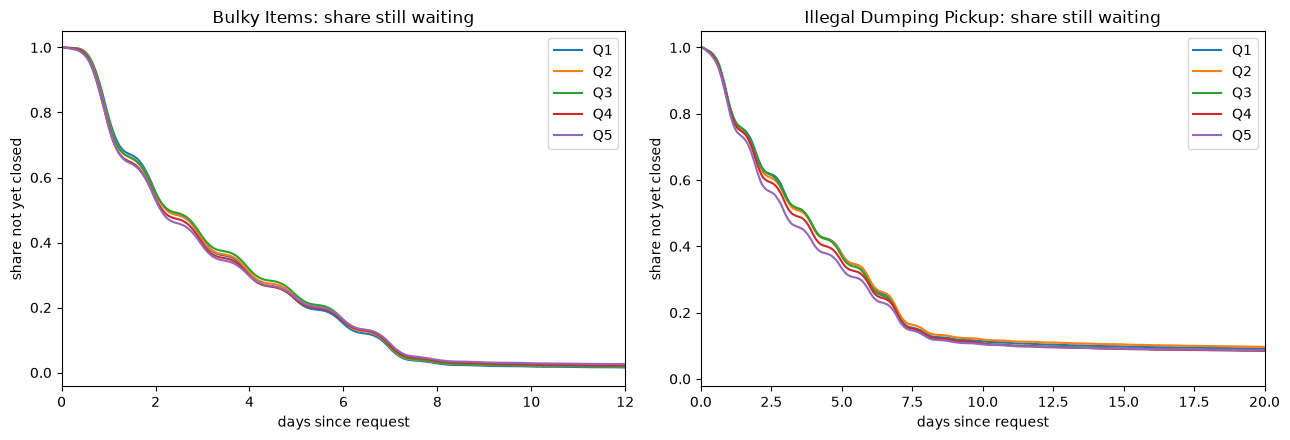

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for rt, ax, xmax in [("Bulky Items", axes[0], 12), ("Illegal Dumping Pickup", axes[1], 20)]:
    for q in range(1, 6):
        d = res[(res.request_type == rt) & (res.quintile == q)]
        KaplanMeierFitter().fit(d.duration, d.closed, label=f"Q{q}").plot_survival_function(ax=ax, ci_show=False)
    ax.set_xlim(0, xmax); ax.set_title(f"{rt}: share still waiting"); ax.set_xlabel("days since request"); ax.set_ylabel("share not yet closed")
plt.tight_layout(); plt.show()

The Kaplan–Meier curves for bulky items and illegal dumping pickup show no visible delay in time to close for tracts with higher limited-English share. For illegal dumping, the highest quintile closes slightly faster, not slower.

## 4. Regression: how big is the gap in days?
Descriptives don't hold income and housing constant. We fit three models. All include request-type fixed effects (so we only compare like with like), median income (logged), renter share, and request year. Standard errors are **clustered by tract**, because requests in the same tract are not independent.

| Model | Outcome | Handles open requests? | Reported as |
|---|---|---|---|
| A. Closed within 30 days | 0/1 | yes (open = not closed) | percentage points |
| B. Log time-to-close | log(days + 1 hour), closed requests only | no, so it is a supporting estimate | % change, converted to days |
| C. Cox, stratified by type | time with censoring | yes | hazard ratio |

The key variable is the limited-English share **per 10 percentage points**.

In [8]:
def prep(d):
    d = d.copy()
    d["lep10"] = d.lep_share * 10
    d["log_inc"] = np.log(d.median_income / 1000)
    d["log_days"] = np.log(d.duration + 1/24)
    d["closed30"] = (d.closed & (d.duration <= 30)).astype(int)
    d["tract"] = d.geoid.astype("category").cat.codes
    return d

def fit_ols(d, y, label):
    m = smf.ols(f"{y} ~ lep10 + log_inc + renter_share + C(request_type) + C(year)", d).fit(
        cov_type="cluster", cov_kwds={"groups": d.tract})
    b, se = m.params["lep10"], m.bse["lep10"]
    return dict(spec=label, outcome=y, n=int(m.nobs), coef=b, ci_low=b-1.96*se, ci_high=b+1.96*se, p=m.pvalues["lep10"])

main = prep(res[res.group == "main"])
resA = fit_ols(main, "closed30", "main, resident only")
closed_main = main[main.closed]
resB = fit_ols(closed_main, "log_days", "main, resident only")
resA, resB

({'spec': 'main, resident only',
  'outcome': 'closed30',
  'n': 2990923,
  'coef': np.float64(0.0001889918310276451),
  'ci_low': np.float64(-0.0011870849170926526),
  'ci_high': np.float64(0.0015650685791479427),
  'p': np.float64(0.787784655658743)},
 {'spec': 'main, resident only',
  'outcome': 'log_days',
  'n': 2959679,
  'coef': np.float64(-0.011829862568701511),
  'ci_low': np.float64(-0.02417657277427819),
  'ci_high': np.float64(0.000516847636875168),
  'p': np.float64(0.060387715056042734)})

In [9]:
# Convert model B's log coefficient into days, using each type's overall median time-to-close
medians = closed_main.groupby("request_type").duration.median()
pct = np.exp(resB["coef"]) - 1
lo, hi = np.exp(resB["ci_low"]) - 1, np.exp(resB["ci_high"]) - 1
out = pd.DataFrame({"median_days": medians, "effect_days_per_10pts": medians * pct,
                    "ci_low": medians * lo, "ci_high": medians * hi}).round(3)
print(f"+10 points limited-English share -> {100*pct:+.2f}% time-to-close (95% CI {100*lo:+.2f}% to {100*hi:+.2f}%)")
print(f"Model A: {100*resA['coef']:+.2f} pp chance of closing within 30 days (95% CI {100*resA['ci_low']:+.2f} to {100*resA['ci_high']:+.2f})")
out.loc[MAIN]

+10 points limited-English share -> -1.18% time-to-close (95% CI -2.39% to +0.05%)
Model A: +0.02 pp chance of closing within 30 days (95% CI -0.12 to +0.16)


,median_days,effect_days_per_10pts,ci_low,ci_high
request_type,,,,
Bulky Items,2.172,-0.026,-0.052,0.001
Illegal Dumping Pickup,3.114,-0.037,-0.074,0.002
Metal/Household Appliances,2.158,-0.025,-0.052,0.001
Electronic Waste,2.099,-0.025,-0.050,0.001
Graffiti Removal,1.512,-0.018,-0.036,0.001


**Model C: Cox proportional hazards.** The Cox model uses the open requests directly. It is slow on millions of rows, so we fit it on a random sample of 60,000 requests per type. A **hazard ratio above 1 means requests close faster**; below 1 means slower.

In [10]:
samp = main.sample(frac=1, random_state=0).groupby("request_type").head(60000)
cx = CoxPHFitter().fit(samp[["duration","closed","lep10","log_inc","renter_share","request_type","tract"]],
                       duration_col="duration", event_col="closed", strata=["request_type"],
                       cluster_col="tract", robust=True)
cx.summary.loc[["lep10","log_inc","renter_share"], ["coef","exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%","p"]].round(4)

,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
lep10,0.0124,1.0125,0.9980,1.0273,0.0922
log_inc,-0.1323,0.8761,0.8415,0.9120,0.0000
renter_share,-0.3249,0.7226,0.6843,0.7631,0.0000


### Models' outcome
- **30-day closure (Model A):** +0.02 percentage points per +10 points of limited-English share (95% CI −0.12 to +0.16). No meaningful difference.
- **Time-to-close (Model B):** −1.2% per +10 points (95% CI −2.4% to +0.05%). At a median of about 2.2 days that is **about −0.03 days (under an hour) per 10 points**. Even across the whole gap between Q1 and Q5 (about 30 points) it is roughly 0.08 days, or **about 2 hours faster**, and the slowest end of the confidence interval is effectively zero.
- **Cox model (Model C), which uses open requests:** hazard ratio 1.009 (95% CI 0.996 to 1.023). A ratio of 1 means no difference, so this agrees.
- **The controls matter more than language.** Higher-income tracts and tracts with more renters see *slower* closure (hazard ratios 0.87 per unit of log income and 0.73 from 0% to 100% renters). That is why the raw 30-day gap for bulky items (98.9% vs 97.9%) disappears once income and housing are held fixed: in this data, language share is largely a stand-in for those characteristics.

**Bottom line for the quick services:** no evidence that limited-English tracts wait longer, and a precise estimate (the confidence interval rules out anything larger than about a 2% slowdown per 10 points).

## 5. Sensitivity checks
Does the answer change if we make different reasonable choices? Each row re-fits model B (log time-to-close) and model A (30-day closure).

| Variant | What changes |
|---|---|
| Main | resident-reported, main request types |
| Include driver reports | the artifact we excluded |
| Trim slowest 1% per type | outliers can't drive the result |
| Tracts ≥ 90% in city | drops tracts that straddle the city boundary |
| 2022–2023 only | one fewer year |
| Slow services | encampments and streetlights (different departments, long waits) |

In [11]:
variants = {
 "Main": main,
 "Include driver reports": prep(df[df.request_type.isin(MAIN)]),
 "Trim slowest 1% per type": main[main.duration <= main.groupby("request_type").duration.transform(lambda s: s.quantile(.99))],
 "Tracts >= 90% in city": main[main.frac_in_city >= 0.9],
 "2022-2023 only": main[main.year <= 2023],
 "Slow services": prep(res[res.group == "slow"]),
}
sens = []
for name, d in variants.items():
    a = fit_ols(d, "closed30", name); b = fit_ols(d[d.closed], "log_days", name)
    sens.append(dict(variant=name, n=a["n"],
                     pct_change_time_per_10pts=100*(np.exp(b["coef"])-1),
                     pct_ci=f"{100*(np.exp(b['ci_low'])-1):+.1f} to {100*(np.exp(b['ci_high'])-1):+.1f}",
                     pp_closed30_per_10pts=100*a["coef"],
                     pp_ci=f"{100*a['ci_low']:+.2f} to {100*a['ci_high']:+.2f}"))
sens = pd.DataFrame(sens).round(2)
sens

,variant,n,pct_change_time_per_10pts,pct_ci,pp_closed30_per_10pts,pp_ci
0,Main,2990923,-1.18,-2.4 to +0.1,0.02,-0.12 to +0.16
1,Include driver reports,3481979,3.45,+0.2 to +6.8,-0.04,-0.14 to +0.07
2,Trim slowest 1% per type,2961011,-1.16,-2.3 to +0.0,0.04,-0.07 to +0.15
3,Tracts >= 90% in city,2979194,-1.17,-2.4 to +0.1,0.02,-0.12 to +0.16
4,2022-2023 only,1922356,-0.82,-2.2 to +0.6,0.02,-0.13 to +0.18
5,Slow services,327786,1.39,-2.7 to +5.7,-0.63,-1.39 to +0.14


**The slow services need the Cox model.** Model B drops open requests, which is a poor choice when 20–33% of encampment and streetlight requests are still open. The Cox model keeps them as "still waiting," so for these types it is the estimate to trust.

In [12]:
slow = prep(res[res.group == "slow"])
sz = slow.sample(frac=1, random_state=0).groupby("request_type").head(60000)
cx2 = CoxPHFitter().fit(sz[["duration","closed","lep10","log_inc","renter_share","request_type","tract"]],
                        duration_col="duration", event_col="closed", strata=["request_type"],
                        cluster_col="tract", robust=True)
cx2.summary.loc[["lep10","log_inc","renter_share"], ["coef","exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%","p"]].round(4)

,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
lep10,-0.0129,0.9872,0.9662,1.0086,0.2384
log_inc,0.1559,1.1687,1.0881,1.2551,0.0000
renter_share,-0.0037,0.9963,0.9018,1.1008,0.9426


### What the sensitivity checks say
- **Stable:** the three variants that stay within the main request types (trimmed outliers, tracts ≥ 90% in the city, 2022–2023 only) give −0.8% to −1.2% per 10 points, all within the main confidence interval.
- **Including driver reports changes the sign** (+3.5%, CI +0.2 to +6.8). That is the artifact we expected: driver tickets close in minutes, and the mix of driver and resident reports differs by neighborhood. 
- **Slow services:** Model B gives +1.4% (CI −2.7 to +5.7), and the Cox model, which handles the many open requests properly, gives a hazard ratio of 0.987 (95% CI 0.966 to 1.009), meaning about 1% slower per 10 points and not statistically distinguishable from zero. The large raw gaps in section 3 disappear after holding income and renter share fixed. The interval is wide enough that a modest slowdown can't be ruled out for these services.
- **The 90-day recent-request check from the brief is moot:** every request has at least nine months of follow-up (requests end Dec 2024; the data run to Oct 2025).

## 6. Save the results for the dashboard and the write-up

In [13]:
km_tbl.to_csv(f"{PROC}/results_speed_km.csv", index=False)
sens.to_csv(f"{PROC}/results_speed_sensitivity.csv", index=False)
out.to_csv(f"{PROC}/results_speed_days.csv")
print("saved")

saved


## What we found
For comparable resident-reported requests, tracts with more limited-English households do **not** wait longer for the city to close bulky-item, illegal-dumping, appliance, e-waste or graffiti requests. A +10-point difference in limited-English share is associated with about 1% *faster* closure (95% CI from 2.4% faster to 0.05% slower), which is a few minutes to under an hour at typical waits, and the 30-day closure rate is essentially unchanged. For encampments and streetlights the estimate is a slight slowdown of about 1% per 10 points, with an interval that includes no difference.

**Limits to state:** (1) tract-level data says nothing about individuals; (2) `ClosedDate` is when the ticket was closed, not necessarily when the problem was fixed, and some departments close tickets administratively; (3) language share is correlated with income, renting and department coverage, so we hold the first two constant but not the third; (4) a null result here is not evidence that language doesn't matter for *reporting*.